![logo](https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/images/notebook-logo.png)

## **Curso**: Residência em Inteligência Artificial
## **Unidade Curricular**: Séries Temporais
## **Professor**: Matheus Vanzan
---

### Setup

* `itertools`: combinações de valores para a busca em grade (grid search)
* `time`: mede o tempo de ajuste de cada modelo
* `numpy` (`np`): cálculos numéricos
* `pandas` (`pd`): tabelas (`DataFrame`) e séries (`Series`)
* `matplotlib.pyplot` (`plt`): gráficos
* `statsmodels`: modelos estatísticos de séries temporais (ARIMA e SARIMA)
* `warnings`: esconde os avisos de convergência do ajuste, que poluem a tela

In [1608]:
import itertools
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [1609]:
warnings.filterwarnings('ignore')

O `PATH` é o endereço base dos dados (um repositório no GitHub). Em cada leitura, somamos a ele o caminho do arquivo.

In [1610]:
PATH = 'https://raw.githubusercontent.com/matheusvanzan/Time-Series-Examples/refs/heads/master/'

## 📌 1 - Sazonalidade

O **ARIMA(p,d,q)** combina um AR de ordem $p$ (a previsão usa os $p$ valores anteriores), $d$ diferenciações (que tiram a tendência) e um MA de ordem $q$ (a previsão usa os $q$ erros anteriores). Vamos aplicá-lo a uma série com **sazonalidade forte**, um padrão que se repete em período fixo, e ver até onde ele consegue ir. É essa sazonalidade que o SARIMA acrescenta ao modelo.

> **Dataset:** o clássico **AirPassengers**, o total de passageiros de uma companhia aérea por mês, de 1949 a 1960 (144 meses, em milhares). A pergunta de previsão: quantos passageiros nos próximos 24 meses?

### 1.1 - Transformação logarítmica

Lemos o arquivo, que tem as colunas `Mes` e `Passageiros`. Os argumentos estão explicados no código:

In [1611]:
df_air = pd.read_csv(
    PATH + 'datasets/air_passengers.csv',
    # nomes das colunas do DataFrame
    names=['Mes', 'Passageiros'],
    # 0: a primeira linha do arquivo é um cabeçalho antigo e é descartada
    header=0,
    # coluna que vira data
    parse_dates=['Mes'],
    # coluna usada como índice
    index_col='Mes',
)

A coluna `Passageiros` é a série. O `.asfreq('MS')` fixa a frequência do índice em mensal, com as datas no início do mês:

A série pura. O `.plot()` do pandas desenha com o `matplotlib`: `figsize` é o tamanho, `title` o título, `ylabel` o rótulo do eixo y e `grid=True` liga a grade:

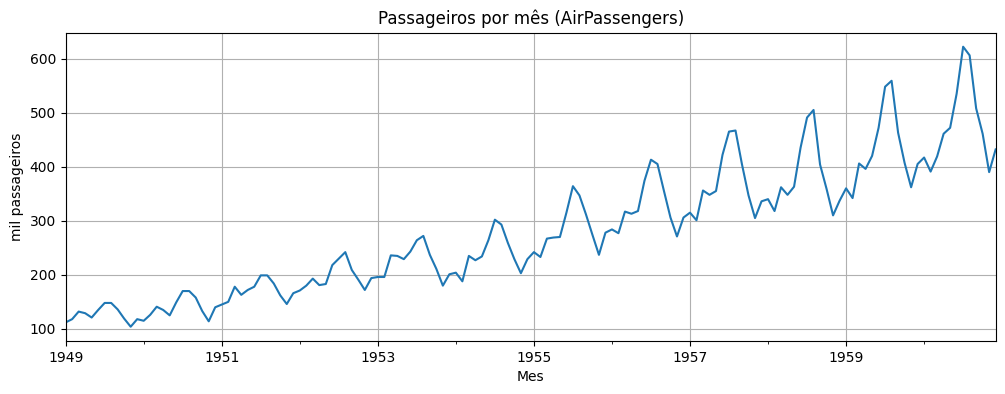

In [1612]:
passageiros = df_air['Passageiros'].asfreq('MS')
passageiros.plot(figsize=(12, 4), title='Passageiros por mês (AirPassengers)', ylabel='mil passageiros', grid=True)
plt.show()

Há **tendência** (o número de passageiros cresce) e **sazonalidade** (um pico no meio de cada ano e um vale no fim). A amplitude da sazonalidade também cresce com o nível da série: é o modelo **multiplicativo**: a sazonalidade multiplica o nível da série, em vez de somar a ele.

O SARIMA só trabalha com séries **aditivas**, em que a amplitude da sazonalidade é constante. O **logaritmo** é o artifício que transforma a série multiplicativa em aditiva. O SARIMA trabalha na escala do log, e `np.exp` desfaz o logaritmo no fim:

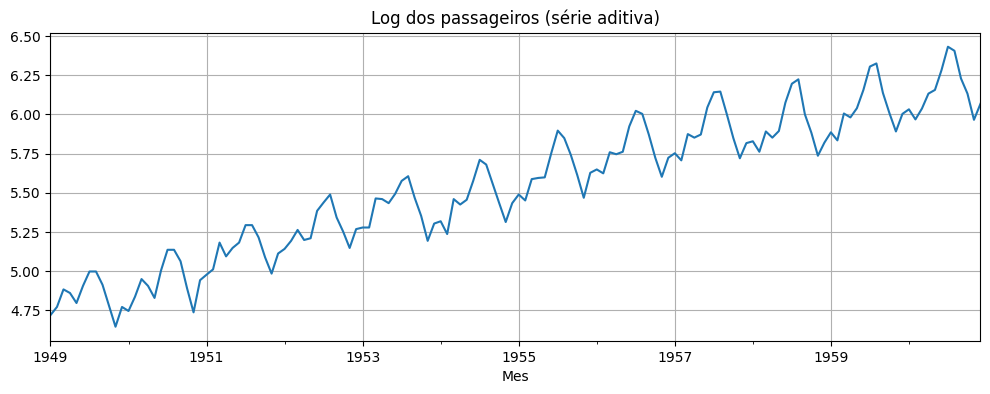

In [1613]:
log_passageiros = np.log(passageiros)
log_passageiros.plot(figsize=(12, 4), title='Log dos passageiros (série aditiva)', grid=True)
plt.show()

Separamos os últimos 24 meses para **teste** e usamos os 120 primeiros para **treino**, os dois na escala original. Os modelos só enxergam o treino, e usam o seu logaritmo (`log_treino`). O teste continua em passageiros, para medir o erro:

In [1614]:
horizonte = 24
treino = passageiros.iloc[:-horizonte]
teste = passageiros.iloc[-horizonte:]

In [1615]:
log_treino = np.log(treino)

In [1616]:
print('Treino:', treino.index[0].date(), 'a', treino.index[-1].date(), '|', len(treino), 'meses')
print('Teste: ', teste.index[0].date(), 'a', teste.index[-1].date(), '|', len(teste), 'meses')

Treino: 1949-01-01 a 1958-12-01 | 120 meses
Teste:  1959-01-01 a 1960-12-01 | 24 meses


O treino e o teste na escala original:

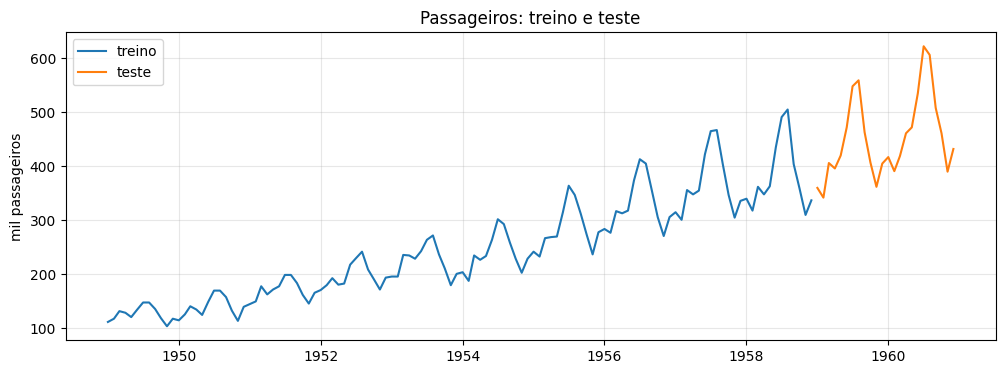

In [1617]:
plt.figure(figsize=(12, 4))
plt.plot(treino, color='tab:blue', label='treino')
plt.plot(teste, color='tab:orange', label='teste')
plt.title('Passageiros: treino e teste')
plt.ylabel('mil passageiros')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 1.2 - Ajuste do ARIMA

Em vez de escolher uma ordem ao acaso, fazemos um **Grid Search** (busca em grade): ajustamos o ARIMA(p,d,q) com $p$, $d$ e $q$ de 0 a 3 (64 modelos) e comparamos pelo **AIC**, o critério de informação de Akaike, que mede o erro do ajuste e penaliza o número de parâmetros (menor é melhor). O `itertools.product(range(4), range(4), range(4))` gera os 64 trios $(p, d, q)$ em um único laço `for`. O argumento `trend` do ARIMA muda com o $d$:

In [1618]:
# A tendência muda conforme o d:
#   d = 0: 'c', a série oscila em torno de uma média constante
#   d = 1: 't', a série diferenciada tem média diferente de zero (a deriva)
#   d = 2 ou 3: 'n', depois de duas ou mais diferenciações não sobra tendência

tendencia = {0: 'c', 1: 't', 2: 'n', 3: 'n'}

**Por que um modelo pode não convergir**

* **Busca numérica:** o `statsmodels` não calcula os parâmetros por fórmula. Ele começa de um chute, calcula a verossimilhança e vai ajustando os parâmetros até a melhora ficar insignificante
* **Limite de iterações:** a busca tem um limite, que é 50 por padrão. Se ele acaba antes de a melhora estabilizar, o resultado é só o ponto onde a busca estava. Isso é "não convergiu"
* **Quando acontece:** é comum quando o modelo tem muitos parâmetros ou raízes perto de 1, como o ARIMA(12,1,1), ou quando as ordens são parecidas e os parâmetros se confundem
* **O perigo:** o modelo não convergido ainda devolve previsões que parecem boas, mas os parâmetros, o AIC e a comparação deixam de ser confiáveis. O `ConvergenceWarning` avisa, e o setup do notebook oculta esse aviso

Por isso aumentamos o limite para `maxiter=1000` e guardamos, para cada modelo, se ele convergiu (`mle_retvals['converged']`) e quantas iterações usou (`mle_retvals['iterations']`):

In [1619]:
%%time
linhas_arima = []

for p, d, q in itertools.product(range(4), range(4), range(4)):
    inicio = time.perf_counter()
    ajuste_g = ARIMA(log_treino, order=(p, d, q), trend=tendencia[d]).fit(method_kwargs={'maxiter': 1000})
    linhas_arima.append({
        'p': p,
        'd': d,
        'q': q,
        'AIC': ajuste_g.aic,
        'parâmetros': len(ajuste_g.params),
        'convergiu': ajuste_g.mle_retvals['converged'],
        'iterações': ajuste_g.mle_retvals['iterations'],
        'tempo (s)': time.perf_counter() - inicio,
    })

CPU times: user 58.8 s, sys: 76.2 ms, total: 58.9 s
Wall time: 39.7 s


Os 3 menores AIC dos 64 candidatos, com o número de parâmetros e o tempo de ajuste de cada um:

In [1620]:
tabela_arima = pd.DataFrame(linhas_arima).sort_values('AIC')
tabela_arima.head(3).round(2)

,p,d,q,AIC,parâmetros,convergiu,iterações,tempo (s)
55,3,1,3,-236.87,8,True,122,5.05
38,2,1,2,-229.31,6,True,86,0.94
37,2,1,1,-224.56,5,True,64,0.51


O melhor é o de menor AIC entre os que convergiram. Guardamos a ordem dele e o nome, para usar no ajuste e nos gráficos:

In [1621]:
melhor_arima = linhas_arima[tabela_arima[tabela_arima['convergiu']].index[0]]
ordem_arima = (melhor_arima['p'], melhor_arima['d'], melhor_arima['q'])

nome_arima = 'ARIMA' + str(ordem_arima)
nome_arima

'ARIMA(3, 1, 3)'

Ajustamos esse modelo e prevemos os 24 meses do teste com `.get_forecast(steps=horizonte)`, em que `horizonte` é o tamanho do teste. O `trend` vem do dicionário `tendencia`, pelo $d$ do modelo:

In [1622]:
ajuste_arima = ARIMA(log_treino, order=ordem_arima, trend=tendencia[ordem_arima[1]]).fit(method_kwargs={'maxiter': 1000})
prev_arima = ajuste_arima.get_forecast(steps=horizonte)

Conferimos se o ajuste do modelo escolhido convergiu, em `mle_retvals`:

In [1623]:
print('Convergiu:', ajuste_arima.mle_retvals['converged'], '| iterações:', ajuste_arima.mle_retvals['iterations'])

Convergiu: True | iterações: 122


O ajuste convergiu, então os parâmetros e o AIC são os finais. Com o limite padrão de 50 iterações ele não convergia, e o AIC saía pior (-227, contra -237 agora). A conclusão é a mesma: o ARIMA de ordem pequena ainda deixa sazonalidade no resíduo.

A previsão contra os valores reais do teste. A previsão está na escala do log, e o `np.exp` a devolve à escala original (mil passageiros):

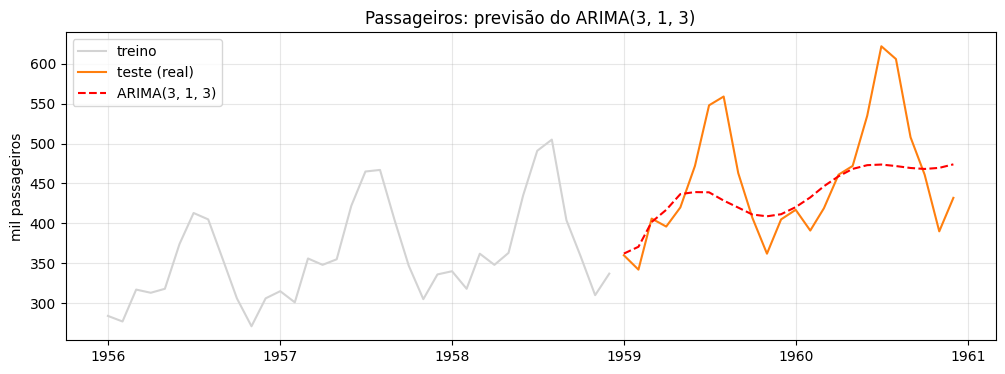

In [1624]:
plt.figure(figsize=(12, 4))
plt.plot(treino.iloc[-36:], color='lightgray', label='treino')
plt.plot(teste, color='tab:orange', label='teste (real)')
plt.plot(np.exp(prev_arima.predicted_mean), color='red', linestyle='--', label=nome_arima)
plt.title('Passageiros: previsão do ' + nome_arima)
plt.ylabel('mil passageiros')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Mesmo com a melhor ordem da grade, o ARIMA prevê uma curva suave, com uma oscilação pequena, que **não reproduz os picos e vales** reais: ele não conhece o padrão que se repete a cada 12 meses. Os valores reais continuam subindo e descendo em cada ano.

A análise do resíduo mostra que ainda há sazonalidade no que o modelo não explicou. O resíduo (real menos previsto de 1 passo) deveria parecer ruído. O primeiro resíduo é o próprio valor inicial da série, sem previsão anterior, então o descartamos. A linha preta marca o zero:

In [1625]:
resid_arima = ajuste_arima.resid.iloc[ordem_arima[1]:]

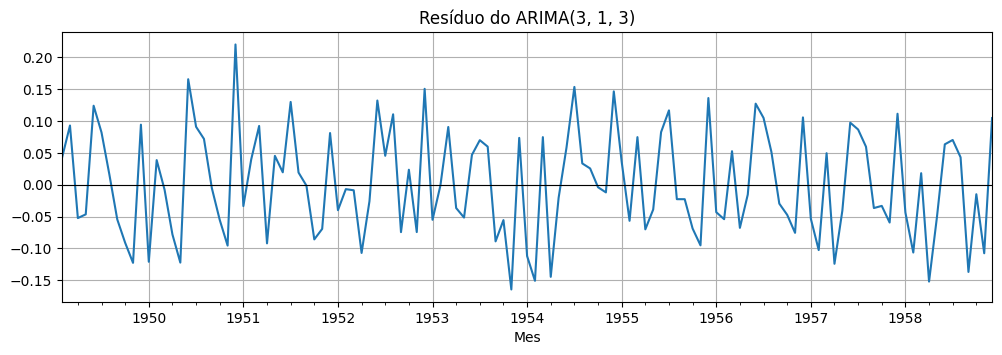

In [1626]:
resid_arima.plot(figsize=(12, 3.5), title='Resíduo do ' + nome_arima, grid=True)
plt.axhline(0, color='black', linewidth=0.8)
plt.show()

O resíduo **não é completamente ruído**: ele sobe e desce em ondas que se repetem a cada 12 meses, o resto de sazonalidade que o modelo não pegou. Ele **tem padrão**, e o ARIMA de ordem pequena não serve para esta série.

### 1.3 - ARIMA de ordem elevada

Em dados mensais, a sazonalidade se repete a cada 12 meses. Guardamos esse período, que o restante do notebook usa:

In [1627]:
periodo_sazonal = 12

Será que um ARIMA de ordem maior consegue acompanhar a sazonalidade? O lag 12 é o **mesmo mês do ano anterior**, e um AR com $p$ até 12 pode olhar para ele. Repetimos o Grid Search completo, com $p$ de 0 a 12 e $d$ e $q$ de 0 a 2 (`itertools.product(range(13), range(3), range(3))`). São 117 candidatos, e o ajuste leva alguns minutos:

In [1628]:
%%time
linhas_arima12 = []

p_range = range(periodo_sazonal + 1)
d_range = range(3)
q_range = range(3)

for p, d, q in itertools.product(p_range, d_range, q_range):
    inicio = time.perf_counter()
    ajuste_g = ARIMA(log_treino, order=(p, d, q), trend=tendencia[d]).fit(method_kwargs={'maxiter': 1000})
    linhas_arima12.append({
        'p': p,
        'd': d,
        'q': q,
        'AIC': ajuste_g.aic,
        'parâmetros': len(ajuste_g.params),
        'convergiu': ajuste_g.mle_retvals['converged'],
        'iterações': ajuste_g.mle_retvals['iterations'],
        'tempo (s)': time.perf_counter() - inicio,
    })

CPU times: user 11min 54s, sys: 1.27 s, total: 11min 55s
Wall time: 7min 16s


Os 3 menores AIC dos 117 candidatos:

In [1629]:
tabela_arima12 = pd.DataFrame(linhas_arima12).sort_values('AIC')
tabela_arima12.head(3).round(2)

,p,d,q,AIC,parâmetros,convergiu,iterações,tempo (s)
112,12,1,1,-379.19,15,True,234,12.20
113,12,1,2,-377.69,16,True,301,15.29
111,12,1,0,-373.99,14,True,190,6.67


O melhor é o de menor AIC entre os que convergiram. Guardamos a ordem dele e o nome:

In [1630]:
melhor_arima12 = linhas_arima12[tabela_arima12[tabela_arima12['convergiu']].index[0]]
ordem_arima12 = (melhor_arima12['p'], melhor_arima12['d'], melhor_arima12['q'])

nome_arima12 = 'ARIMA' + str(ordem_arima12)
nome_arima12

'ARIMA(12, 1, 1)'

Ajustamos esse modelo e prevemos os 24 meses:

In [1631]:
ajuste_arima12 = ARIMA(log_treino, order=ordem_arima12, trend=tendencia[ordem_arima12[1]]).fit(method_kwargs={'maxiter': 1000})
prev_arima12 = ajuste_arima12.get_forecast(steps=horizonte)

Conferimos se o ajuste convergiu:

In [1632]:
print('Convergiu:', ajuste_arima12.mle_retvals['converged'], '| iterações:', ajuste_arima12.mle_retvals['iterations'])

Convergiu: True | iterações: 234


Convergiu. Com o limite padrão de 50 iterações, não: o AIC saía um pouco pior (-378, contra -379 agora), e a escolha e a conclusão da seção são as mesmas.

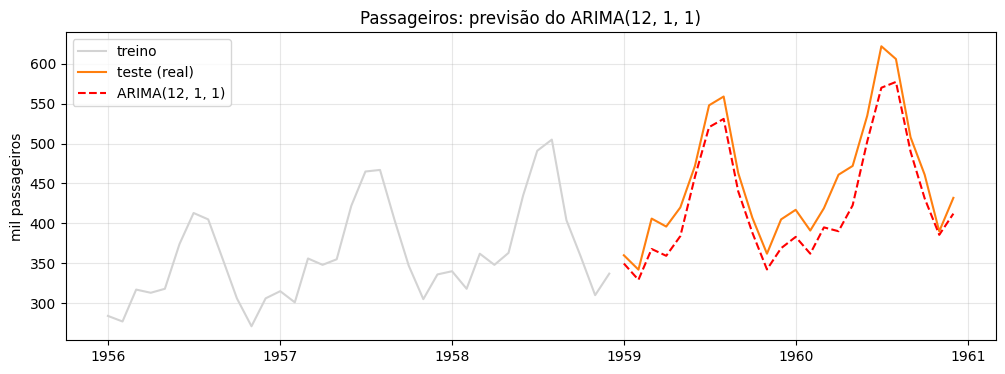

In [1633]:
plt.figure(figsize=(12, 4))
plt.plot(treino.iloc[-36:], color='lightgray', label='treino')
plt.plot(teste, color='tab:orange', label='teste (real)')
plt.plot(np.exp(prev_arima12.predicted_mean), color='red', linestyle='--', label=nome_arima12)
plt.title('Passageiros: previsão do ' + nome_arima12)
plt.ylabel('mil passageiros')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Agora a previsão **acompanha o padrão anual**: o ARIMA com $p = 12$ aprendeu a olhar para o mesmo mês do ano anterior. O resíduo:

In [1634]:
resid_arima12 = ajuste_arima12.resid.iloc[ordem_arima12[1]:]

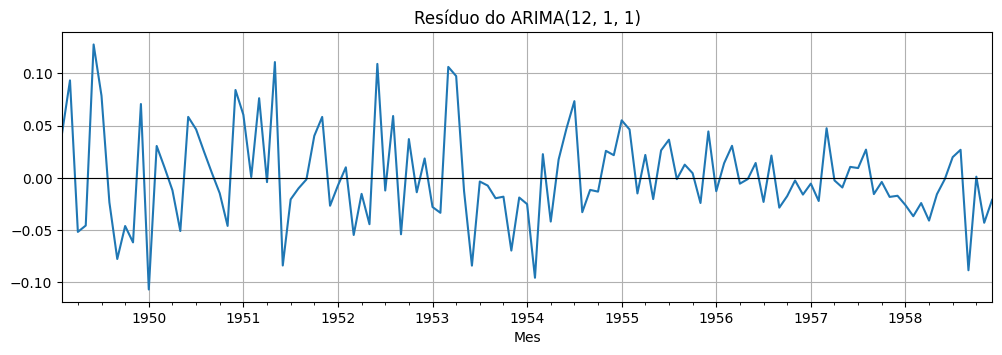

In [1635]:
resid_arima12.plot(figsize=(12, 3.5), title='Resíduo do ' + nome_arima12, grid=True)
plt.axhline(0, color='black', linewidth=0.8)
plt.show()

O resíduo é bem menor e parece mais com ruído. Visualmente, o ARIMA(12,1,1) parece se ajustar a serie. Para entender como o modelo conseguiu isso, olhamos o peso do AR em cada lag, de 1 a 12 meses atrás:

In [1636]:
lags_ar = range(1, ordem_arima12[0] + 1)
pesos_ar = ajuste_arima12.params[['ar.L' + str(i) for i in lags_ar]]
pesos_ar.index = lags_ar
maior_lag = pesos_ar.abs().idxmax()

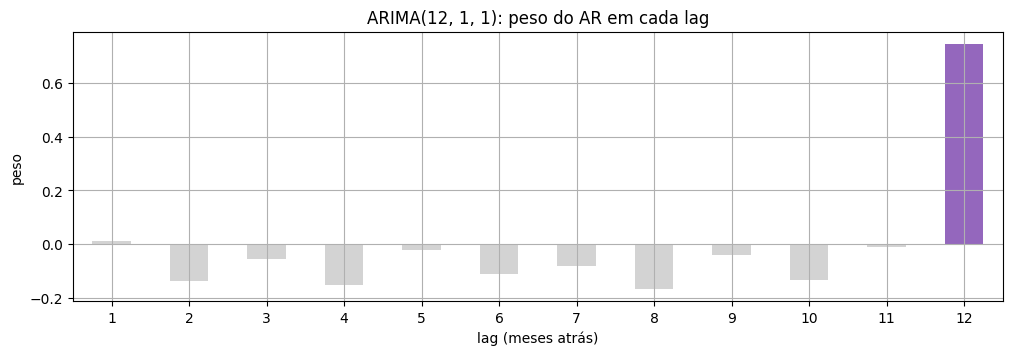

In [1637]:
cores = ['tab:purple' if lag == maior_lag else 'lightgray' for lag in pesos_ar.index]
pesos_ar.plot.bar(figsize=(12, 3.5), color=cores, rot=0,
                  title=nome_arima12 + ': peso do AR em cada lag', xlabel='lag (meses atrás)', ylabel='peso', grid=True)
plt.show()

O peso do **lag 12 é 0,74**, bem maior que os outros 11: o modelo usou o lag 12, o mesmo mês do ano anterior, para copiar a sazonalidade. Então o ARIMA resolve o problema? Para responder, olhamos o **custo** dessa solução. Da grade de 117 modelos, pegamos os ARIMA(p,1,1), com $p$ de 0 a 12:

In [1638]:
custo_p = tabela_arima12[(tabela_arima12['d'] == ordem_arima12[1]) & (tabela_arima12['q'] == ordem_arima12[2])].sort_values('p')

O AIC e o tempo de ajuste de cada ARIMA(p,1,1):

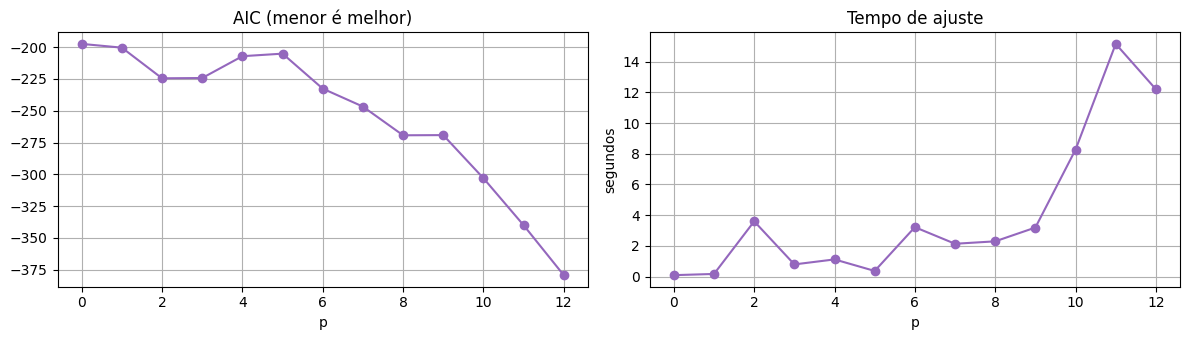

In [1639]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.5))
custo_p.plot(x='p', y='AIC', marker='o', color='tab:purple', ax=eixos[0], legend=False, grid=True,
             title='AIC (menor é melhor)', xlabel='p')
custo_p.plot(x='p', y='tempo (s)', marker='o', color='tab:purple', ax=eixos[1], legend=False, grid=True,
             title='Tempo de ajuste', xlabel='p', ylabel='segundos')
plt.tight_layout()
plt.show()

**Conclusão da seção:** o ARIMA com $p = 12$ **funciona** na previsão: acompanha o padrão anual. Mas ele é uma solução cara:

* **Só um lag importa:** dos 12 pesos do AR, só o do lag 12 é grande (0,74). Os outros 11 estão lá porque o ARIMA precisa de todos os lags de 1 a 12 para chegar ao lag 12, e o modelo fica com **15 parâmetros**
* **A melhora chega tarde:** até $p = 6$ o AIC fica entre -197 e -233, e só cai de verdade a partir de $p = 9$ (-269), até $p = 11$ (-340) e $p = 12$ (-379)
* **O custo cresce com a ordem:** cada $p$ a mais é um parâmetro a mais e um ajuste mais demorado, e a grade de 117 modelos leva muito mais tempo que a de 64
* **A ordem acompanha o período:** com ciclo de 12 meses, $p = 12$. Com um ciclo de 24 horas, seria $p = 24$, e o custo cresceria junto

O SARIMA acrescenta ao modelo uma **parte sazonal**, que olha direto para os lags $m, 2m, 3m$, sem precisar dos lags intermediários. A seguir, vemos como ele faz isso com poucos parâmetros.

## 📌 2 - Diferenciação sazonal

### 2.1 - Diferença sazonal

A diferença simples, $x_t - x_{t-1}$, compara cada mês com o **mês anterior** e tira a tendência. Foi isso que o ARIMA da seção anterior fez por dentro: a tendência saiu, mas o padrão anual continuou no resíduo.

A **diferença sazonal** compara cada valor com o **mesmo ponto do ciclo anterior**, $m$ períodos atrás:

$$\Delta_m x_t = x_t - x_{t-m}$$

No pandas, é o `.diff(m)`. O argumento é a **defasagem**: cada valor é subtraído do valor $m$ posições antes. Nos passageiros, o período é $m = 12$. Os 12 primeiros meses ficam sem valor (`NaN`), porque a diferença sazonal **consome um ciclo inteiro** de dados:

In [1640]:
periodo_sazonal

12

In [1641]:
diferenca_sazonal = log_treino.diff(periodo_sazonal)

In [1642]:
diferenca_sazonal.head(periodo_sazonal + 2)

,Passageiros
Mes,
1949-01-01,NaN
1949-02-01,NaN
1949-03-01,NaN
1949-04-01,NaN
1949-05-01,NaN
1949-06-01,NaN
1949-07-01,NaN
1949-08-01,NaN
1949-09-01,NaN


### 2.2 - Efeito da diferença sazonal

O log dos passageiros antes e depois da diferença sazonal:

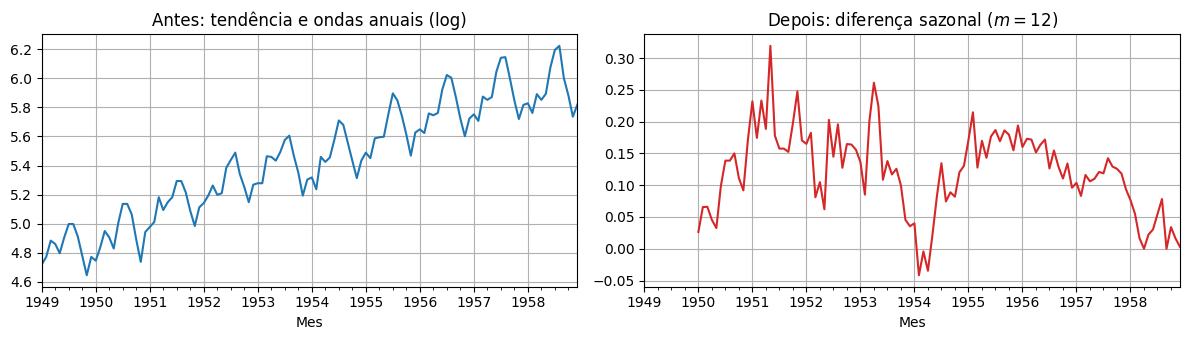

In [1643]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.5))
log_treino.plot(ax=eixos[0], title='Antes: tendência e ondas anuais (log)', grid=True)
diferenca_sazonal.plot(ax=eixos[1], color='tab:red', title='Depois: diferença sazonal ($m = ' + str(periodo_sazonal) + '$)', grid=True)
plt.tight_layout()
plt.show()

Depois da diferença, as ondas anuais saíram. Mas a série ainda não oscila em torno de uma **média constante**: ela começa mais alta e desce (a média dos 2 primeiros anos é 0,15, e a dos 2 últimos é 0,07). A **tendência** ainda está lá.

### 2.3 - Diferença simples e sazonal ($d$ e $D$)

Quando a diferença sazonal não remove toda a tendência, aplicamos as duas diferenciações: primeiro a **sazonal** (ordem $D$) e depois a **simples** (ordem $d$). A ordem das duas não altera o resultado. A diferença simples sobre a sazonal:

In [1644]:
diferenca_dupla = diferenca_sazonal.diff()

In [1645]:
diferenca_dupla.dropna().head()

,Passageiros
Mes,
1950-02-01,0.039164
1950-03-01,0.000361
1950-04-01,-0.020496
1950-05-01,-0.012939
1950-06-01,0.066148


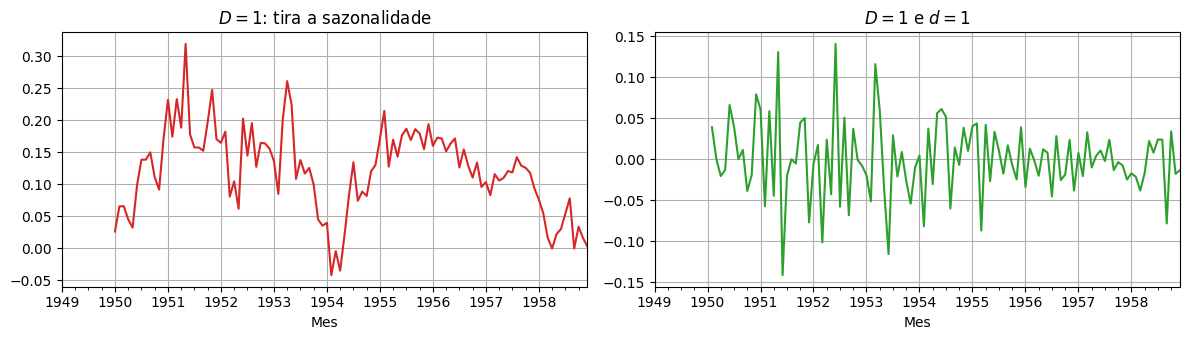

In [1646]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.5))
diferenca_sazonal.plot(ax=eixos[0], color='tab:red', title='$D = 1$: tira a sazonalidade', grid=True)
diferenca_dupla.plot(ax=eixos[1], color='tab:green', title='$D = 1$ e $d = 1$', grid=True)
plt.tight_layout()
plt.show()

Com $D = 1$ e $d = 1$, a série oscila em torno de **zero**, sem tendência e sem sazonalidade. Na prática, $D$ costuma ser 0 ou 1 e $d$ costuma ser 0, 1 ou 2. Diferenciar muitas vezes costuma apenas adicionar ruído (sobrediferenciação).

## 📌 3 - Modelagem SARIMA

O **SARIMA** (*Seasonal ARIMA*) é o ARIMA com uma parte sazonal. A notação tem as duas partes:

$$\text{SARIMA}(p, d, q)(P, D, Q, m)$$

* **$(p, d, q)$**, a parte não sazonal: AR, diferenciação simples e MA, nos lags curtos (1, 2, 3 períodos atrás)
* **$(P, D, Q, m)$**, a parte sazonal: as mesmas ideias nos lags sazonais ($m$, $2m$, $3m$ períodos atrás). $P$ é o AR sazonal, $D$ a diferenciação sazonal e $Q$ o MA sazonal. $m$ é o período

Modelar uma série com o SARIMA é definir esses sete valores. O período $m$ vem do calendário, e $D$ e $d$ vêm da análise da seção 2. Os demais, $p$, $q$, $P$ e $Q$, são hiperparâmetros: a forma de escolhê-los é o **Grid Search**.

Em `statsmodels`, o SARIMA é a classe **`SARIMAX`**. O X é de variáveis externas: sem elas, o `SARIMAX` é o SARIMA. As duas partes viram duas tuplas, `order=(p, d, q)` e `seasonal_order=(P, D, Q, m)`.

O período $m$ vem do calendário: em dados mensais, 12 (o `periodo_sazonal`, da seção 1.3). A seção 2 mostrou que a diferença sazonal ($D = 1$) tira a sazonalidade e que a simples ($d = 1$) tira a tendência que sobra. Guardamos os dois valores e a tendência do `SARIMAX`: com $d = 1$ e $D = 1$, a série diferenciada já fica em torno de zero, e não há constante (`'n'`):

In [1647]:
# diferenciações escolhidas na seção 2: uma simples (d) e uma sazonal (D)
d_sarima = 1
D_sarima = 1

# com d = 1 e D = 1, a série diferenciada já fica em torno de zero: sem constante
tendencia_sarima = 'n'

### 3.1 - Grid Search de $p$, $q$, $P$ e $Q$

Com $m$, $D$ e $d$ definidos, falta definir as ordens $p, q$ (parte não sazonal) e $P, Q$ (parte sazonal). Em vez de adivinhar, testamos algumas combinações pequenas e deixamos o **AIC** decidir: é o mesmo Grid Search, agora com quatro ordens. Retomamos o **AirPassengers** (a variável `log_treino`) e variamos $p$ e $q$ de 0 a 2 e $P$ e $Q$ de 0 a 1.

> Fixamos $m$, $D$ e $d$ nos valores do passo anterior: nesta busca, o AIC compara só modelos com os mesmos $d$ e $D$, porque a série diferenciada muda com eles.

Cada candidato é um par (ordem, ordem sazonal). O `itertools.product` gera as combinações $(p, q, P, Q)$ em um único laço `for`, e `range(3)` percorre 0, 1 e 2:

In [1648]:
candidatos = []

for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
    candidatos.append(((p, d_sarima, q), (P, D_sarima, Q, periodo_sazonal)))

O número de candidatos, 3 × 3 × 2 × 2:

In [1649]:
len(candidatos)

36

### 3.2 - AIC e BIC

Comparamos os candidatos pelo AIC e pelo BIC: menor é melhor nos dois. O BIC é parecido com o AIC, mas penaliza mais o número de parâmetros. Para cada candidato, ajustamos o `SARIMAX` e guardamos o AIC, o BIC, o número de parâmetros, se a otimização convergiu (`mle_retvals['converged']`) e quantas iterações ela usou (`mle_retvals['iterations']`): um modelo que não convergiu não é confiável, mesmo com um bom AIC. O argumento `maxiter=1000` sobe o limite de iterações da busca (o padrão é 50). O argumento `trend` é a tendência: `'n'` (nenhuma), quando há $d = 1$ e $D = 1$, ou `'c'` (constante), quando só há a diferença sazonal. O ajuste dos 36 candidatos leva menos de 1 minuto:

In [1650]:
%%time
linhas_aic = []

for ordem_c, sazonal_c in candidatos:
    ajuste_c = SARIMAX(log_treino, order=ordem_c, seasonal_order=sazonal_c, trend=tendencia_sarima).fit(disp=False, maxiter=1000)
    linhas_aic.append({
        'modelo': 'SARIMA' + str(ordem_c) + str(sazonal_c),
        'AIC': ajuste_c.aic,
        'BIC': ajuste_c.bic,
        'parâmetros': len(ajuste_c.params),
        'convergiu': ajuste_c.mle_retvals['converged'],
        'iterações': ajuste_c.mle_retvals['iterations'],
    })

CPU times: user 1min 10s, sys: 115 ms, total: 1min 10s
Wall time: 42.8 s


O $\Delta$AIC é a diferença para o menor AIC: valores abaixo de 2 indicam modelos com **suporte semelhante**, um empate prático. A tabela, ordenada pelo AIC:

In [1651]:
tabela_aic = pd.DataFrame(linhas_aic)
tabela_aic['ΔAIC'] = tabela_aic['AIC'] - tabela_aic['AIC'].min()
tabela_aic = tabela_aic.round(1).sort_values('AIC')

Os 5 menores AIC:

In [1652]:
tabela_aic.head(5)

,modelo,AIC,BIC,parâmetros,convergiu,iterações,ΔAIC
5,"SARIMA(0, 1, 1)(0, 1, 1, 12)",-389.0,-381.0,3,True,24,0.0
13,"SARIMA(1, 1, 0)(0, 1, 1, 12)",-388.6,-380.6,3,False,14,0.4
7,"SARIMA(0, 1, 1)(1, 1, 1, 12)",-387.2,-376.5,4,True,27,1.8
9,"SARIMA(0, 1, 2)(0, 1, 1, 12)",-387.1,-376.4,4,True,31,1.9
15,"SARIMA(1, 1, 0)(1, 1, 1, 12)",-386.8,-376.1,4,False,29,2.2


O menor AIC é o **SARIMA(0,1,1)(0,1,1,12)**, o modelo clássico do AirPassengers. A coluna `convergiu` mostra quais candidatos merecem confiança: o (1,1,0)(0,1,1,12), a 0,4 ponto do menor AIC, **não convergiu**, mesmo com `maxiter=1000` (a busca também pode emperrar numa região plana da verossimilhança, e não só por falta de iterações), e por isso é descartado. Entre os que convergiram, os demais ficam a 1,8 ponto ou mais e têm mais parâmetros, e no empate fica o modelo **mais simples**: o (0,1,1)(0,1,1,12), que também tem o menor BIC. É o modelo escolhido.

### 3.3 - Ajuste do SARIMA

Guardamos a ordem do modelo de menor AIC entre os que convergiram, e o nome dele:

In [1653]:
ordem_sarima, ordem_sazonal = candidatos[tabela_aic[tabela_aic['convergiu']].index[0]]
nome_sarima = 'SARIMA' + str(ordem_sarima) + str(ordem_sazonal)
nome_sarima

'SARIMA(0, 1, 1)(0, 1, 1, 12)'

Ajustamos o modelo à série de treino, com a mesma sequência do ARIMA: criar o modelo, `SARIMAX(...)`, e chamar `.fit()`. O argumento `disp=False` não mostra o relatório de cada iteração da otimização. As seções seguintes usam esse modelo:

In [1654]:
ajuste_sarima = SARIMAX(log_treino, order=ordem_sarima, seasonal_order=ordem_sazonal, trend=tendencia_sarima).fit(disp=False, maxiter=1000)

Os parâmetros estimados. Os termos com prefixo `S` são os sazonais (por exemplo, `ma.S.L12`), e `sigma2` é a variância do erro:

In [1655]:
ajuste_sarima.params.round(3)

,0
ma.L1,-0.343
ma.S.L12,-0.541
sigma2,0.001


Neste modelo, `ma.L1` é o peso $\theta$ do MA (o erro do mês anterior) e `ma.S.L12` é o peso $\Theta$ do MA sazonal (o erro de 12 meses atrás). Os dois são negativos ($\theta = -0{,}343$ e $\Theta = -0{,}541$). Com só **3 parâmetros**, o SARIMA faz o que o ARIMA(12,1,1) fez com 15.

Para ver como o ajuste acompanha a série, comparamos o valor real com o valor ajustado, o previsto de 1 passo (`.fittedvalues`), na escala original (`np.exp`). A diferença consome os primeiros valores, que não servem, e `descartar` guarda quantos são: um ciclo para cada diferença sazonal ($D \times m$), mais um para cada diferença simples ($d$):

In [1656]:
descartar = ordem_sazonal[1] * ordem_sazonal[3] + ordem_sarima[1]

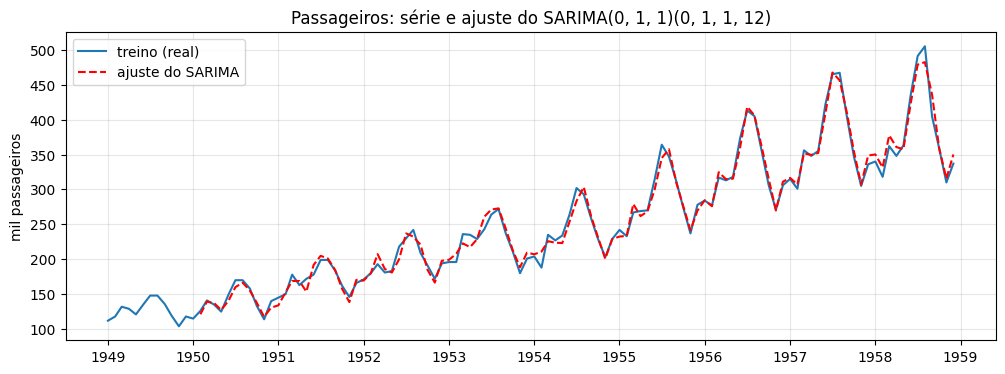

In [1657]:
plt.figure(figsize=(12, 4))
plt.plot(treino, color='tab:blue', label='treino (real)')
plt.plot(np.exp(ajuste_sarima.fittedvalues.iloc[descartar:]), color='red', linestyle='--', label='ajuste do SARIMA')
plt.title('Passageiros: série e ajuste do ' + nome_sarima)
plt.ylabel('mil passageiros')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

O ajuste acompanha a série de perto: o pico e o vale de cada ano e a amplitude crescente. Como é uma previsão de 1 passo (cada mês usa o valor real dos meses anteriores), o ajuste dentro do treino sempre fica próximo. A previsão para o futuro, que é o teste de verdade, vem na seção 4.1.

## 🎯 Momento de praticar

Aplique o roteiro da modelagem à **planta B**, outra fábrica, com medidas **a cada hora**. O arquivo tem as colunas `timestamp` e `potencia_kw`. Os passos:

1. Carregue o dataset, mostre o início e **plote** a série pura
2. Calcule o consumo **médio diário** (`resample('D').mean()` e `.interpolate()`)
3. Defina o período pelo calendário (ciclo semanal, $m = 7$) e **separe o teste** (as duas últimas semanas): todas as escolhas seguintes usam só o treino
4. Aplique a **diferença sazonal** ao treino, plotando a série antes e depois
5. Monte a grade de candidatos, com $p$ e $q$ de 0 a 2 e $P$ e $Q$ de 0 a 1 ($D = 1$ e $d = 0$)
6. Compare **AIC e BIC** dos candidatos no treino (com a tendência `'c'`, porque só há a diferença sazonal) e fique com o menor
7. Compare o modelo escolhido com uma **baseline**, a repetição da última semana, no teste (o **MAE** de cada um)

Para carregar o dataset, use:

```python
df_b = pd.read_csv(
    PATH + 'datasets/consumo_energia_planta_b.csv',
    parse_dates=['timestamp'],
    index_col='timestamp',
)
potencia_b = df_b['potencia_kw']
```

**Passo 1:** carregue o dataset, mostre o início e plote a série pura.

In [1658]:
df_b = pd.read_csv(PATH + 'datasets/consumo_energia_planta_b.csv', parse_dates=['timestamp'], index_col='timestamp')

In [1659]:
df_b.head()

,potencia_kw
timestamp,
2024-01-01 00:00:00,256.6
2024-01-01 01:00:00,259.6
2024-01-01 02:00:00,253.8
2024-01-01 03:00:00,247.4
2024-01-01 04:00:00,251.9


In [1660]:
potencia_b = df_b['potencia_kw']

In [1661]:
potencia_b.head()

,potencia_kw
timestamp,
2024-01-01 00:00:00,256.6
2024-01-01 01:00:00,259.6
2024-01-01 02:00:00,253.8
2024-01-01 03:00:00,247.4
2024-01-01 04:00:00,251.9


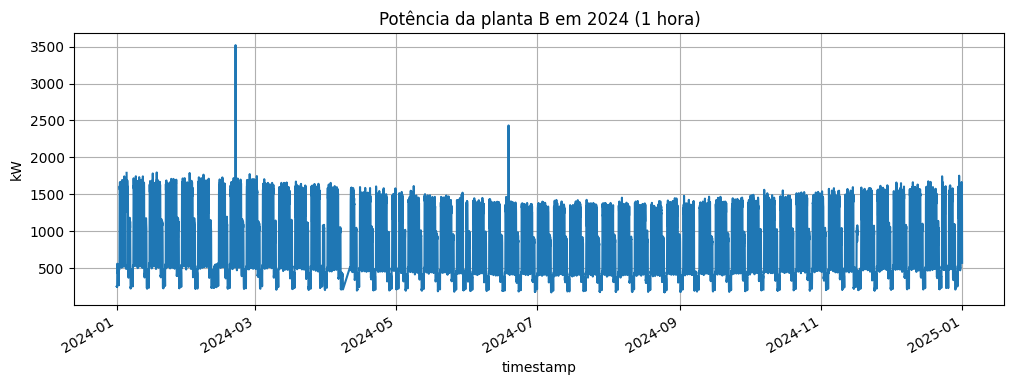

In [1662]:
potencia_b.plot(figsize=(12, 4), title='Potência da planta B em 2024 (1 hora)', ylabel='kW', grid=True)
plt.show()

**Passo 2:** calcule o consumo médio diário. O `resample('D').mean()` agrupa as medidas por dia e calcula a média de cada dia, e o `.interpolate()` preenche os dias sem medida.

In [1663]:
diario_b = potencia_b.resample('D').mean().interpolate()

In [1664]:
diario_b.head()

,potencia_kw
timestamp,
2024-01-01,423.500000
2024-01-02,1215.466667
2024-01-03,1228.904167
2024-01-04,1237.229167
2024-01-05,1226.239130


**Passo 3:** pelo calendário, o ciclo de uma série diária é a semana, $m = 7$ (`periodo_diario`). Separamos as duas últimas semanas, dois ciclos, para o **teste**, antes de qualquer escolha: o teste só entra na avaliação final, e o treino decide a diferença, a grade e o modelo:

In [1665]:
periodo_diario = 7

In [1666]:
horizonte_b = 2 * periodo_diario
treino_b = diario_b.iloc[:-horizonte_b]
teste_b = diario_b.iloc[-horizonte_b:]

**Passo 4:** a diferença sazonal, `.diff(m)`, tira o padrão semanal. Aplicamos ao treino:

In [1667]:
diferenca_sazonal_b = treino_b.diff(periodo_diario)

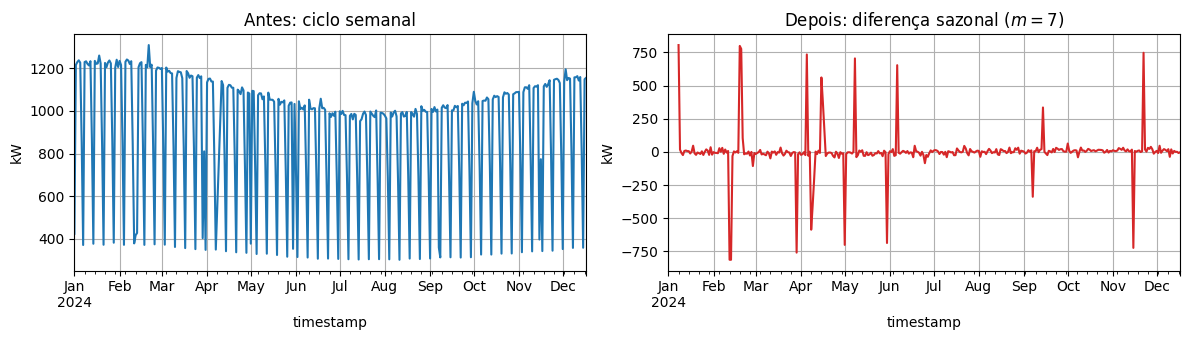

In [1668]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.5))
treino_b.plot(ax=eixos[0], title='Antes: ciclo semanal', ylabel='kW', grid=True)
diferenca_sazonal_b.plot(ax=eixos[1], color='tab:red', title='Depois: diferença sazonal ($m = 7$)', ylabel='kW', grid=True)
plt.tight_layout()
plt.show()

Depois da diferença, o padrão semanal saiu, e a série oscila em torno de uma média constante, perto de zero. Então $D = 1$ e $d = 0$.

**Passo 5:** monte os candidatos, como no Grid Search da seção 3. Com $d = 0$, o `itertools.product` gera as combinações $(p, q, P, Q)$:

In [1669]:
candidatos_b = []

for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
    candidatos_b.append(((p, 0, q), (P, 1, Q, periodo_diario)))

**Passo 6:** compare AIC e BIC dos 36 candidatos, ajustados só no **treino** (o ajuste leva menos de 1 minuto). Guarde também se cada ajuste convergiu e fique com o menor AIC **entre os que convergiram**:

In [1670]:
%%time
linhas_b = []

for ordem_c, sazonal_c in candidatos_b:
    ajuste_c = SARIMAX(treino_b, order=ordem_c, seasonal_order=sazonal_c, trend='c').fit(disp=False, maxiter=1000)
    linhas_b.append({
        'modelo': 'SARIMA' + str(ordem_c) + str(sazonal_c),
        'AIC': ajuste_c.aic,
        'BIC': ajuste_c.bic,
        'parâmetros': len(ajuste_c.params),
        'convergiu': ajuste_c.mle_retvals['converged'],
        'iterações': ajuste_c.mle_retvals['iterations'],
    })

CPU times: user 1min 47s, sys: 203 ms, total: 1min 48s
Wall time: 1min 6s


In [1671]:
tabela_b = pd.DataFrame(linhas_b)
tabela_b['ΔAIC'] = tabela_b['AIC'] - tabela_b['AIC'].min()
tabela_b = tabela_b.round(1).sort_values('AIC')

In [1672]:
tabela_b.head(5)

,modelo,AIC,BIC,parâmetros,convergiu,iterações,ΔAIC
21,"SARIMA(1, 0, 2)(0, 1, 1, 7)",4285.6,4308.7,6,True,52,0.0
29,"SARIMA(2, 0, 1)(0, 1, 1, 7)",4286.3,4309.4,6,True,47,0.7
23,"SARIMA(1, 0, 2)(1, 1, 1, 7)",4287.5,4314.4,7,True,71,1.9
31,"SARIMA(2, 0, 1)(1, 1, 1, 7)",4287.5,4314.4,7,True,52,1.8
13,"SARIMA(1, 0, 0)(0, 1, 1, 7)",4294.2,4309.6,4,True,23,8.6


**Passo 7:** a baseline é a previsão mais simples que repete o ciclo: cada dia é igual ao mesmo dia da semana anterior. Se o SARIMA não ganhar dela, o modelo não se justifica. Ajustamos o modelo escolhido no treino e comparamos no teste:

In [1673]:
ordem_b, sazonal_b = candidatos_b[tabela_b[tabela_b['convergiu']].index[0]]
ajuste_b = SARIMAX(treino_b, order=ordem_b, seasonal_order=sazonal_b, trend='c').fit(disp=False, maxiter=1000)
prev_b = ajuste_b.get_forecast(steps=horizonte_b).predicted_mean

In [1674]:
ultima_semana = treino_b.iloc[-periodo_diario:].values
baseline_b = pd.Series(np.tile(ultima_semana, 2), index=teste_b.index)

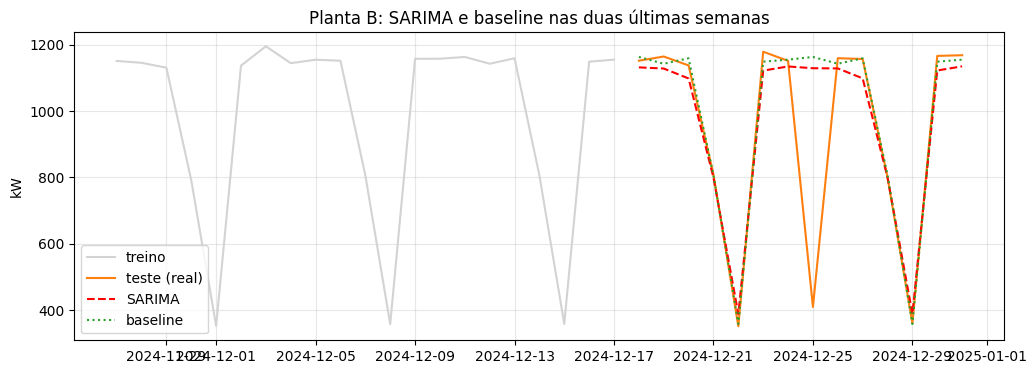

In [1675]:
plt.figure(figsize=(12, 4))
plt.plot(treino_b.iloc[-3 * periodo_diario:], color='lightgray', label='treino')
plt.plot(teste_b, color='tab:orange', label='teste (real)')
plt.plot(prev_b, color='red', linestyle='--', label='SARIMA')
plt.plot(baseline_b, color='tab:green', linestyle=':', label='baseline')
plt.title('Planta B: SARIMA e baseline nas duas últimas semanas')
plt.ylabel('kW')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [1676]:
pd.DataFrame({
    'SARIMA': [(teste_b - prev_b).abs().mean()],
    'baseline': [(teste_b - baseline_b).abs().mean()],
}, index=['MAE (kW)']).round(2)

,SARIMA,baseline
MAE (kW),80.67,64.94


**Conclusão:**

* **Diferenças:** com $m = 7$, a diferença sazonal tira o ciclo semanal, e a série fica em torno de uma média constante, então $D = 1$ e $d = 0$
* **Melhor modelo:** o menor AIC e o menor BIC, no treino, são do SARIMA(1,0,2)(0,1,1,7), com AIC de 4285,6, BIC de 4308,7 e 6 parâmetros. Todos os candidatos convergiram com `maxiter=1000`
* **Empate:** o (2,0,1)(0,1,1,7) fica a 0,7 ponto de AIC, com os mesmos 6 parâmetros. Os dois com a parte sazonal completa, $P = Q = 1$, ficam a 1,8 e 1,9 ponto, com 7 parâmetros. O AR(1) simples, (1,0,0)(0,1,1,7), tem só 4 parâmetros, mas fica a 8,6 pontos
* **Resultado:** o SARIMA reproduz o desenho da semana, com o vale de domingo bem previsto
* **Baseline:** nas duas últimas semanas (o teste, que não participou da escolha), a baseline (repetir a última semana) erra 64,94 kW em média, e o SARIMA erra 80,67 kW. Aqui a baseline **vence**: o menor AIC entre os candidatos não garante ganhar de uma regra simples. Sem essa comparação, o modelo pareceria bom
* **Nível:** o SARIMA acerta o desenho da semana, mas prevê os dias úteis (fora o Natal) sempre abaixo do real, de 17 a 58 kW. O MA sazonal tem peso próximo de $-1$ ($\Theta = -0{,}94$) e suaviza o perfil, com uma média ponderada de várias semanas passadas, que incluem semanas mais baixas. A baseline copia só a última semana, que estava no nível alto
* **Feriado:** o dia 25/12 (Natal) cai a 409 kW, e os dois modelos erram esse dia, porque nenhum modelo de série temporal prevê um feriado sozinho. Esse dia pesa no MAE, mas não explica a derrota do SARIMA: sem ele, o SARIMA erra 31,5 kW e a baseline 11,9 kW. Para os feriados, seria preciso uma variável externa

## 📌 4 - Comparativo de modelos

Nesta seção, os três modelos ajustados (`ajuste_arima`, `ajuste_arima12` e `ajuste_sarima`) são comparados entre si e com uma **baseline**, a previsão mais simples possível: repetir o ciclo anterior. Se um modelo não ganha da baseline, ele não se justifica. A comparação tem quatro pontos: a **previsão**, o **resíduo**, o **intervalo** e o **erro**.

### 4.1 - Previsão

A baseline repete os últimos 12 meses do treino (`periodo_sazonal`): cada mês previsto é igual ao mesmo mês do ano anterior. Para os 24 meses do teste, o ano é repetido duas vezes (`np.tile`):

In [1677]:
baseline = pd.Series(np.tile(treino.iloc[-periodo_sazonal:].values, horizonte // periodo_sazonal), index=teste.index)

Os dois ARIMA já foram previstos (`prev_arima` e `prev_arima12`). Prevemos os 24 meses do teste com o SARIMA, com `.get_forecast(steps=horizonte)`:

In [1678]:
prev_sarima = ajuste_sarima.get_forecast(steps=horizonte)

Reunimos as quatro previsões na escala original (`np.exp`) e a cor de cada modelo:

In [1679]:
previsoes = {
    'baseline': baseline,
    nome_arima: np.exp(prev_arima.predicted_mean),
    nome_arima12: np.exp(prev_arima12.predicted_mean),
    nome_sarima: np.exp(prev_sarima.predicted_mean),
}
cores = {nome_arima: 'tab:purple', nome_arima12: 'tab:brown', nome_sarima: 'red', 'baseline': 'tab:green'}

As quatro previsões contra o teste, no mesmo gráfico. Os valores do ARIMA(3,1,3) fora do quadro ficam cortados:

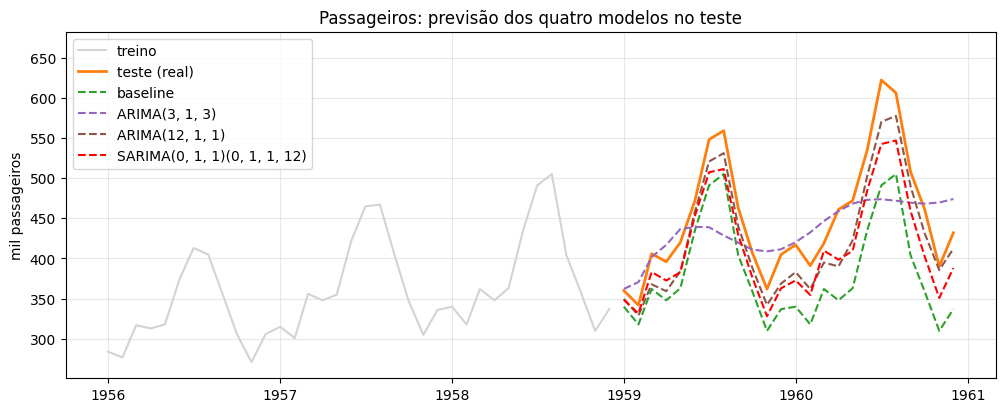

In [1680]:
plt.figure(figsize=(12, 4.5))
plt.plot(treino.iloc[-36:], color='lightgray', label='treino')
plt.plot(teste, color='tab:orange', linewidth=2, label='teste (real)')

for nome, prev in previsoes.items():
    plt.plot(prev, color=cores[nome], linestyle='--', label=nome)
plt.ylim(treino.iloc[-36:].min() - 20, teste.max() + 60)
plt.title('Passageiros: previsão dos quatro modelos no teste')
plt.ylabel('mil passageiros')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

O ARIMA(3,1,3) é uma curva suave, com oscilação pequena, que não reproduz os picos e vales. O ARIMA(12,1,1) e o SARIMA **repetem o padrão sazonal** e acompanham a tendência. A baseline repete o desenho do ano anterior, mas fica **abaixo** do real: ela ignora o crescimento de um ano para o outro.

### 4.2 - Resíduo

O resíduo é o real menos o previsto de 1 passo, e fica em `.resid`. Os ARIMA já têm o resíduo (`resid_arima` e `resid_arima12`, seções 1.2 e 1.3). No SARIMA, descartamos os primeiros valores, os de inicialização (`descartar`, da seção 3.3). Na baseline, o previsto de 1 passo é o mesmo mês do ano anterior, `.shift(periodo_sazonal)`, e o primeiro ano não tem previsto:

In [1681]:
resid_sarima = ajuste_sarima.resid.iloc[descartar:]
resid_baseline = (log_treino - log_treino.shift(periodo_sazonal)).dropna()

Se o modelo capturou a sazonalidade, o resíduo deve parecer ruído. Os quatro resíduos lado a lado, na mesma escala (o log):

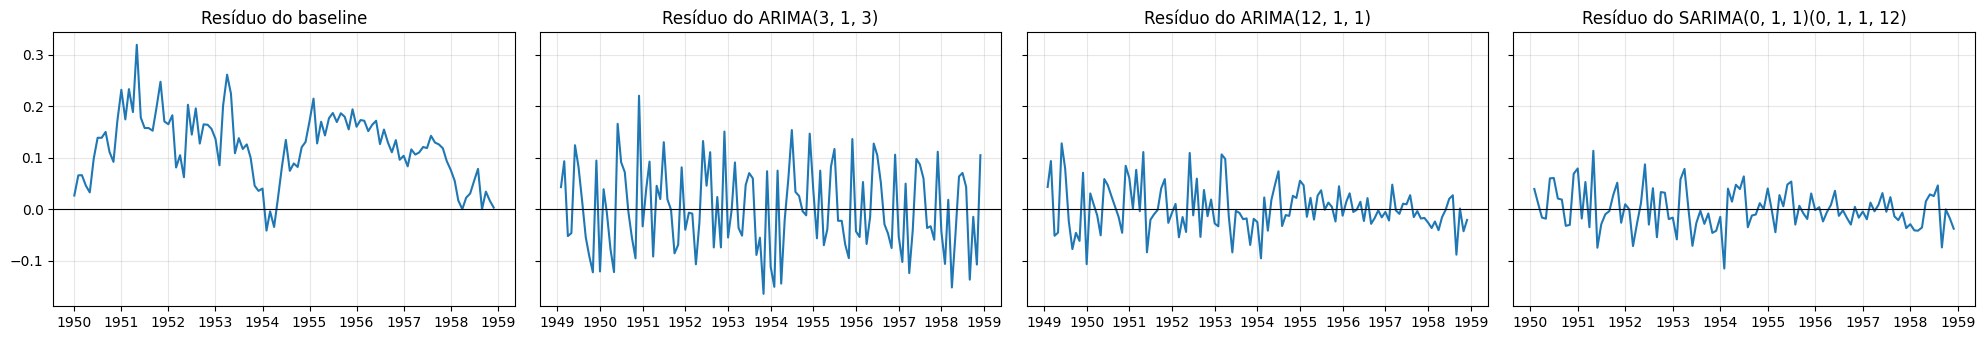

In [1682]:
fig, eixos = plt.subplots(1, 4, figsize=(20, 3.5), sharey=True)

for eixo, resid, nome in [
    (eixos[0], resid_baseline, 'baseline'),
    (eixos[1], resid_arima, nome_arima),
    (eixos[2], resid_arima12, nome_arima12),
    (eixos[3], resid_sarima, nome_sarima),
]:
    eixo.plot(resid, color='tab:blue')
    eixo.axhline(0, color='black', linewidth=0.8)
    eixo.set_title('Resíduo do ' + nome)
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

O resíduo do ARIMA(3,1,3) tem **ondas anuais**: sobrou o padrão sazonal. No ARIMA(12,1,1) e no SARIMA, o resíduo oscila ao acaso em torno de zero, e os dois capturaram a sazonalidade. O da baseline não tem as ondas, mas fica **acima de zero**: ela captura a sazonalidade, e não a tendência. A média e o desvio-padrão dos quatro:

In [1683]:
pd.DataFrame({
    'baseline': [resid_baseline.mean(), resid_baseline.std()],
    nome_arima: [resid_arima.mean(), resid_arima.std()],
    nome_arima12: [resid_arima12.mean(), resid_arima12.std()],
    nome_sarima: [resid_sarima.mean(), resid_sarima.std()],
}, index=['média', 'desvio-padrão']).round(3)

,baseline,"ARIMA(3, 1, 3)","ARIMA(12, 1, 1)","SARIMA(0, 1, 1)(0, 1, 1, 12)"
média,0.122,0.002,0.002,0.000
desvio-padrão,0.066,0.084,0.045,0.039


A média dos três modelos fica perto de zero, e a da baseline é de 0,122: ela erra sempre para o mesmo lado, porque ignora o crescimento de um ano para o outro. O desvio-padrão do ARIMA(3,1,3) é cerca do dobro dos do ARIMA(12,1,1) e do SARIMA (0,045 e 0,039), o SARIMA com 3 parâmetros contra 15.

### 4.3 - Intervalo de previsão

O **intervalo de confiança** vem de `.conf_int(alpha=...)`. O argumento `alpha` é a probabilidade de o valor real cair **fora** da faixa: `alpha=0.2` dá o intervalo de 80%. O resultado é uma tabela com o limite inferior e o superior de cada mês, na escala do log, e o `np.exp` a devolve à escala original. A baseline não é um modelo estatístico e não tem intervalo. O intervalo de 80% dos três modelos:

In [1684]:
ic_arima = np.exp(prev_arima.conf_int(alpha=0.2))
ic_arima12 = np.exp(prev_arima12.conf_int(alpha=0.2))
ic80 = np.exp(prev_sarima.conf_int(alpha=0.2))
intervalos = {nome_arima: ic_arima, nome_arima12: ic_arima12, nome_sarima: ic80}

As quatro previsões, cada uma no seu painel, com a faixa de 80% (a baseline fica sem faixa):

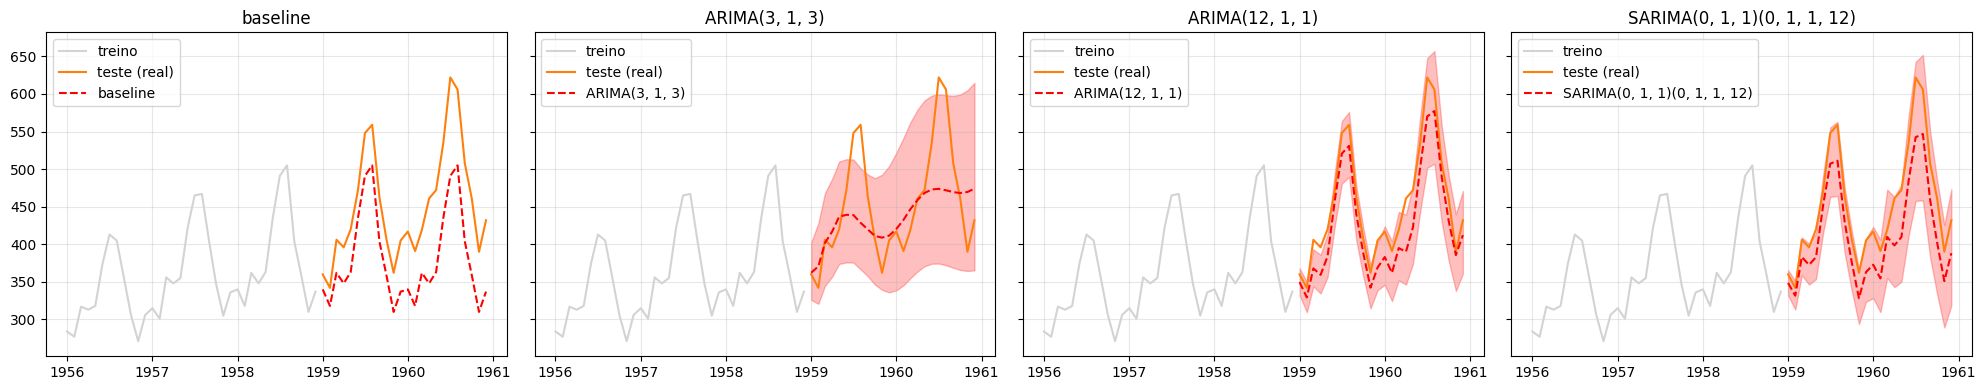

In [1685]:
fig, eixos = plt.subplots(1, 4, figsize=(20, 4), sharey=True)

for eixo, (nome, prev) in zip(eixos, previsoes.items()):
    eixo.plot(treino.iloc[-36:], color='lightgray', label='treino')
    eixo.plot(teste, color='tab:orange', label='teste (real)')
    eixo.plot(prev, color='red', linestyle='--', label=nome)
    if nome in intervalos:
        ic = intervalos[nome]
        eixo.fill_between(ic.index, ic.iloc[:, 0], ic.iloc[:, 1], color='red', alpha=0.25)
    eixo.set_ylim(treino.iloc[-36:].min() - 20, teste.max() + 60)
    eixo.set_title(nome)
    eixo.legend()
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

A faixa abre com o horizonte (quanto mais longe, maior a incerteza) e é **assimétrica**, mais larga para cima, por causa do `np.exp`. A previsão é uma faixa, e não uma linha certa. Para medir a faixa, contamos a **largura média** e a **cobertura**, a fração dos valores reais que cai dentro dela. Um intervalo de 80% deve cobrir cerca de 80%:

In [1686]:
linhas_intervalo = []

for nome, ic in intervalos.items():
    dentro = (teste >= ic.iloc[:, 0]) & (teste <= ic.iloc[:, 1])
    linhas_intervalo.append({
        'modelo': nome,
        'cobertura': dentro.mean(),
        'largura média': (ic.iloc[:, 1] - ic.iloc[:, 0]).mean(),
    })

In [1687]:
pd.DataFrame(linhas_intervalo).set_index('modelo').round(2)

,cobertura,largura média
modelo,,
"ARIMA(3, 1, 3)",0.83,176.22
"ARIMA(12, 1, 1)",0.79,85.55
"SARIMA(0, 1, 1)(0, 1, 1, 12)",0.96,105.66


A faixa do ARIMA(3,1,3) é a mais larga (176, contra 86 do ARIMA(12,1,1) e 106 do SARIMA), e ele cobre 83% dos valores reais: cobre bastante porque a faixa é larga. A cobertura mais próxima dos 80% esperados é a do ARIMA(12,1,1), 79%, com a faixa mais estreita. A do SARIMA, 96%, fica bem acima: a faixa dele é mais larga do que o necessário nestes 24 meses. Cobrir mais não é melhor, porque um intervalo muito largo cobre tudo e informa pouco. Com só 24 meses, a cobertura também varia de uma amostra para outra.

### 4.4 - Erro de previsão

Para medir o erro da previsão, usamos três medidas no teste: quanto menor, melhor. O **MAE** é o erro médio absoluto, e o **RMSE** é a raiz do erro quadrático médio, que pesa mais os erros grandes. As duas estão na unidade da série (mil passageiros). O **MAPE** é o erro percentual absoluto médio: o erro de cada mês dividido pelo valor real, em %, e depois a média. Por ser um percentual, não depende da unidade, mas exagera quando o valor real é pequeno. Primeiro, o erro dos quatro ao longo do teste:

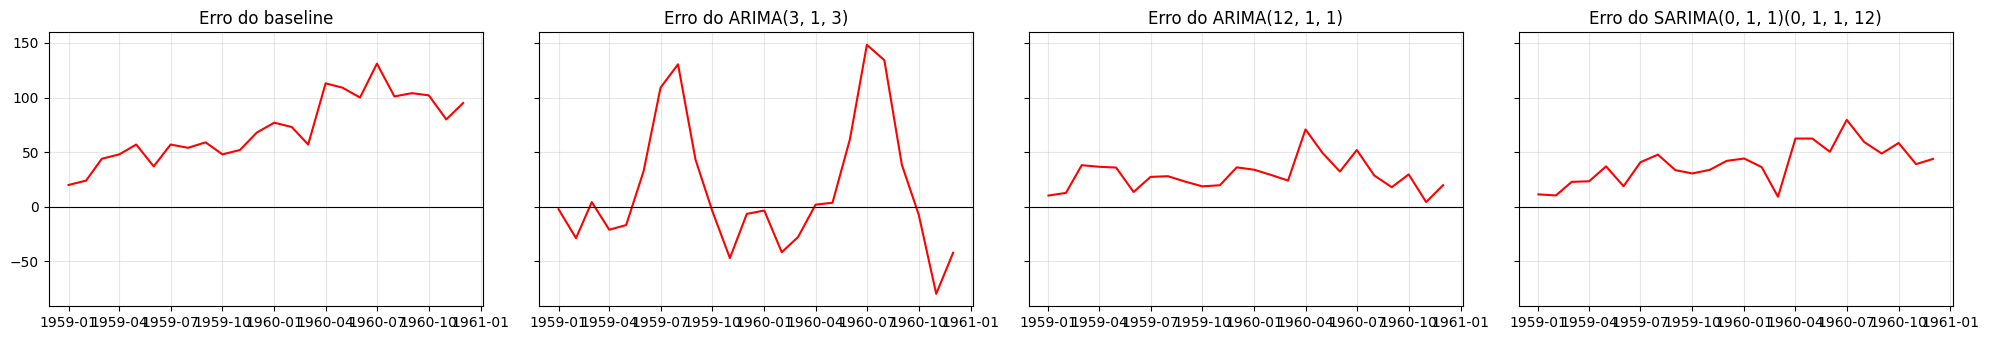

In [1688]:
fig, eixos = plt.subplots(1, 4, figsize=(20, 3.5), sharey=True)

for eixo, (nome, prev) in zip(eixos, previsoes.items()):
    eixo.plot(teste - prev, color='red')
    eixo.axhline(0, color='black', linewidth=0.8)
    eixo.set_title('Erro do ' + nome)
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

O erro do ARIMA(3,1,3) é grande nos picos e vales do ano. O da baseline fica **sempre positivo** (a previsão abaixo do real, nos 24 meses), e os do ARIMA(12,1,1) e do SARIMA ficam mais próximos de zero. Os números, por modelo:

In [1689]:
linhas_erro = []

for nome, prev in previsoes.items():
    erro = teste - prev
    linhas_erro.append({
        'modelo': nome,
        'MAE': erro.abs().mean(),
        'RMSE': np.sqrt((erro ** 2).mean()),
        'MAPE (%)': (erro / teste).abs().mean() * 100,
    })

In [1690]:
pd.DataFrame(linhas_erro).set_index('modelo').round(2)

,MAE,RMSE,MAPE (%)
modelo,,,
baseline,71.25,76.99,15.52
"ARIMA(3, 1, 3)",43.15,61.79,8.77
"ARIMA(12, 1, 1)",28.85,32.19,6.36
"SARIMA(0, 1, 1)(0, 1, 1, 12)",39.44,43.18,8.51


Os três modelos erram menos que a baseline (MAE de 71,25 mil passageiros por mês e MAPE de 15,5%). O ARIMA(12,1,1) tem o menor erro, 28,85 (6,4%), e o SARIMA erra 39,44 (8,5%). O ARIMA(3,1,3) erra 43,15 (8,8%), um MAE parecido com o do SARIMA, mas o RMSE dele, 61,79, é bem maior que o do SARIMA, 43,18: os erros grandes estão nos picos e vales, que ele não reproduz. Neste teste, o ARIMA de ordem 12 erra menos que o SARIMA. A diferença está no custo: o ARIMA(12,1,1) precisa de **15 parâmetros** e de uma busca com 117 candidatos, e o SARIMA fica próximo dele com **3 parâmetros**, com a sazonalidade escrita de forma explícita e fácil de interpretar.

## 🎯 Momento de praticar

Faça a comparação entre o ARIMA e o SARIMA com **outra série**: a temperatura média mensal de Nottingham (1920 a 1939). O arquivo tem as colunas `Month` e `Temperature`. O ciclo é anual, $m = 12$. Os passos:

1. Carregue o dataset, mostre o início e **plote** a série
2. Separe o **treino** e o **teste** (os últimos 12 meses)
3. Ajuste o **ARIMA(1,0,1)** (com `trend='c'`, a média da temperatura) e o **SARIMA(1,0,0)(0,1,1,12)** (a temperatura não tem tendência)
4. Preveja os 12 meses do teste com intervalo de **95%** e plote os dois modelos
5. Calcule a **cobertura** e a **largura média** do intervalo dos dois
6. Compare o **MAE** dos dois com o de uma **baseline**, a repetição do ano anterior

Para carregar o dataset, use:

```python
df_temp = pd.read_csv(
    PATH + 'datasets/temperatura_media_mensal.csv',
    parse_dates=['Month'],
    index_col='Month',
)
temp = df_temp['Temperature'].asfreq('MS')
```

**Passo 1:** carregue o dataset, mostre o início e plote a série.

In [1691]:
df_temp = pd.read_csv(PATH + 'datasets/temperatura_media_mensal.csv', parse_dates=['Month'], index_col='Month')

In [1692]:
df_temp.head()

,Temperature
Month,
1920-01-01,40.6
1920-02-01,40.8
1920-03-01,44.4
1920-04-01,46.7
1920-05-01,54.1


A coluna `Temperature` é a série, com frequência mensal:

In [1693]:
temp = df_temp['Temperature'].asfreq('MS')

In [1694]:
temp.head()

,Temperature
Month,
1920-01-01,40.6
1920-02-01,40.8
1920-03-01,44.4
1920-04-01,46.7
1920-05-01,54.1


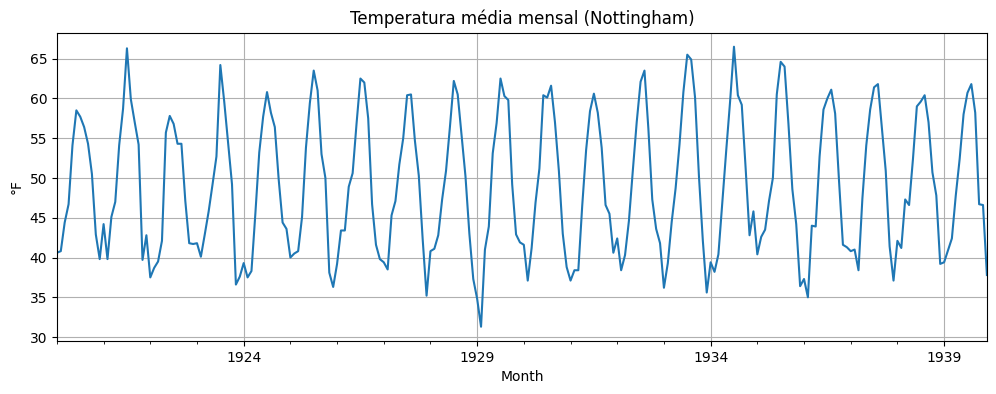

In [1695]:
temp.plot(figsize=(12, 4), title='Temperatura média mensal (Nottingham)', ylabel='°F', grid=True)
plt.show()

**Passo 2:** separe o treino e o teste (os últimos 12 meses).

In [1696]:
treino_t = temp.iloc[:-12]

In [1697]:
treino_t.tail()

,Temperature
Month,
1938-08-01,60.4
1938-09-01,57.0
1938-10-01,50.7
1938-11-01,47.8
1938-12-01,39.2


In [1698]:
teste_t = temp.iloc[-12:]

In [1699]:
teste_t.head()

,Temperature
Month,
1939-01-01,39.4
1939-02-01,40.9
1939-03-01,42.4
1939-04-01,47.8
1939-05-01,52.4


**Passo 3:** ajuste o ARIMA(1,0,1) e o SARIMA(1,0,0)(0,1,1,12).

In [1700]:
ordem_t_arima = (1, 0, 1)
nome_t_arima = 'ARIMA' + str(ordem_t_arima)
ajuste_t_arima = SARIMAX(treino_t, order=ordem_t_arima, trend='c').fit(disp=False)

In [1701]:
ordem_t_sarima = (1, 0, 0)
ordem_t_sazonal = (0, 1, 1, periodo_sazonal)
nome_t_sarima = 'SARIMA' + str(ordem_t_sarima) + str(ordem_t_sazonal)
ajuste_t_sarima = SARIMAX(treino_t, order=ordem_t_sarima, seasonal_order=ordem_t_sazonal).fit(disp=False)

In [1702]:
print('Parâmetros do', nome_t_arima + ':', ajuste_t_arima.params.round(2).to_dict())
print('Parâmetros do', nome_t_sarima + ':', ajuste_t_sarima.params.round(2).to_dict())

Parâmetros do ARIMA(1, 0, 1): {'intercept': 13.28, 'ar.L1': 0.73, 'ma.L1': 0.38, 'sigma2': 20.39}
Parâmetros do SARIMA(1, 0, 0)(0, 1, 1, 12): {'ar.L1': 0.26, 'ma.S.L12': -0.89, 'sigma2': 5.45}


**Passo 4:** preveja os 12 meses do teste com intervalo de 95% e plote.

In [1703]:
prev_t_arima = ajuste_t_arima.get_forecast(steps=len(teste_t))
prev_t_sarima = ajuste_t_sarima.get_forecast(steps=len(teste_t))

In [1704]:
prev_t_sarima.predicted_mean.round(1).head()

,predicted_mean
1939-01-01,39.6
1939-02-01,39.1
1939-03-01,42.4
1939-04-01,46.3
1939-05-01,52.5


In [1705]:
ic_t_arima = prev_t_arima.conf_int(alpha=0.05)
ic_t_sarima = prev_t_sarima.conf_int(alpha=0.05)

In [1706]:
ic_t_sarima.round(1).head()

,lower Temperature,upper Temperature
1939-01-01,35.1,44.2
1939-02-01,34.4,43.9
1939-03-01,37.6,47.1
1939-04-01,41.6,51.1
1939-05-01,47.8,57.3


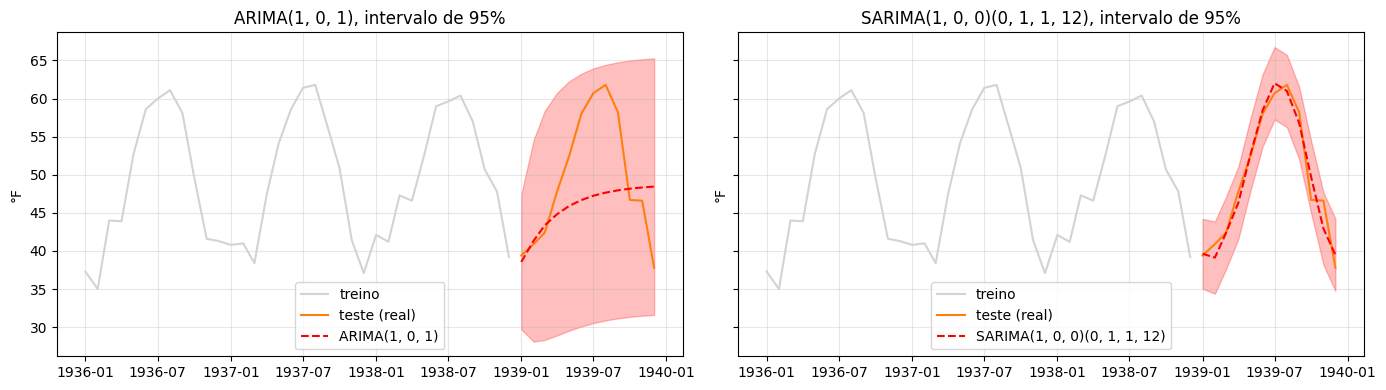

In [1707]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

for eixo, prev, ic, nome in [
    (eixos[0], prev_t_arima, ic_t_arima, nome_t_arima),
    (eixos[1], prev_t_sarima, ic_t_sarima, nome_t_sarima),
]:
    eixo.plot(treino_t.iloc[-36:], color='lightgray', label='treino')
    eixo.plot(teste_t, color='tab:orange', label='teste (real)')
    eixo.plot(prev.predicted_mean, color='red', linestyle='--', label=nome)
    eixo.fill_between(ic.index, ic.iloc[:, 0], ic.iloc[:, 1], color='red', alpha=0.25)
    eixo.set_title(nome + ', intervalo de 95%')
    eixo.set_ylabel('°F')
    eixo.legend()
    eixo.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Passo 5:** calcule a cobertura e a largura média dos intervalos.

In [1708]:
intervalos_t = {nome_t_arima: ic_t_arima, nome_t_sarima: ic_t_sarima}

In [1709]:
linhas_intervalo_t = []

for nome, ic in intervalos_t.items():
    dentro = (teste_t >= ic.iloc[:, 0]) & (teste_t <= ic.iloc[:, 1])
    linhas_intervalo_t.append({
        'modelo': nome,
        'cobertura': dentro.mean(),
        'largura média': (ic.iloc[:, 1] - ic.iloc[:, 0]).mean(),
    })

In [1710]:
pd.DataFrame(linhas_intervalo_t).set_index('modelo').round(2)

,cobertura,largura média
modelo,,
"ARIMA(1, 0, 1)",1.0,31.12
"SARIMA(1, 0, 0)(0, 1, 1, 12)",1.0,9.46


**Passo 6:** a baseline repete o ciclo: cada mês é igual ao mesmo mês do ano anterior (os últimos 12 meses do treino). O modelo só se justifica se errar menos que ela:

In [1711]:
baseline_t = pd.Series(treino_t.iloc[-periodo_sazonal:].values, index=teste_t.index)

In [1712]:
previsoes_t = {
    nome_t_arima: prev_t_arima.predicted_mean,
    nome_t_sarima: prev_t_sarima.predicted_mean,
    'baseline': baseline_t,
}
linhas_erro_t = []

for nome, prev in previsoes_t.items():
    linhas_erro_t.append({'modelo': nome, 'MAE (°F)': (teste_t - prev).abs().mean()})

In [1713]:
pd.DataFrame(linhas_erro_t).set_index('modelo').round(2)

,MAE (°F)
modelo,
"ARIMA(1, 0, 1)",6.23
"SARIMA(1, 0, 0)(0, 1, 1, 12)",1.34
baseline,1.70


**Conclusão:**

* **Ajuste:** o SARIMA estima $\phi = 0{,}26$ e $\Theta = -0{,}89$ (um MA sazonal forte, típico de uma sazonalidade estável). O ARIMA(1,0,1) estima um AR de 0,73 e um MA de 0,38
* **Intervalos:** o ARIMA, sem sazonalidade, prevê uma curva suave em direção à média, e a faixa de 95% tem 31,1 °F de largura. O SARIMA reproduz o padrão do ano, com uma faixa de 9,5 °F. Os dois cobrem 100% dos 12 valores reais, mas só o SARIMA tem uma faixa útil
* **Escolha:** o SARIMA, que descreve a sazonalidade explicitamente, é o modelo adequado
* **Baseline:** repetir o ano anterior erra 1,70 °F em média (MAE). O SARIMA erra 1,34 °F, menos que a baseline, e o ARIMA erra 6,23 °F, bem mais. Só o SARIMA justifica o custo do modelo

## 📌 Conclusão

* A **sazonalidade** é um padrão que se repete em período fixo $m$. O ARIMA de ordem pequena não a modela: o gráfico do resíduo mostra **ondas que se repetem a cada $m$ períodos**
* Um ARIMA com $p$ até 12 acompanha o padrão anual, porque o lag 12 é o mesmo mês do ano anterior, mas gasta **15 parâmetros**. O SARIMA faz o mesmo com 3, de forma explícita
* O SARIMA só trabalha com séries **aditivas**: em séries com amplitude crescente, usamos o **logaritmo** antes do modelo e o `np.exp` depois
* A **diferenciação sazonal** ($\Delta_m x_t = x_t - x_{t-m}$, em `.diff(m)`) remove o padrão e consome um ciclo de dados. $D$ costuma ser 0 ou 1, e a diferença simples ($d$) só entra se ainda sobrar tendência
* O **SARIMA(p,d,q)(P,D,Q,m)** é o ARIMA mais uma parte sazonal, com AR, diferenciação e MA nos lags $m, 2m, 3m$. No `statsmodels`, é a classe `SARIMAX`
* O período $m$ vem do **calendário** e se confirma na **decomposição**. Teste períodos plausíveis e fique com o menor que estabiliza a série
* $p, q, P$ e $Q$ saem de uma **busca em grade** por **AIC** (e BIC), com os mesmos $d$ e $D$. No empate, fica o modelo mais simples
* O **resíduo** do SARIMA deve parecer ruído, sem as ondas sazonais
* A previsão repete o padrão sazonal e vem com um **intervalo** (`.conf_int`) que abre com o horizonte, bem mais estreito que o do ARIMA de ordem pequena